# Classical recovery from an order-finding sample

This notebook replays freshly executed arithmetic-circuit records and executes the original integer-only CF/offset/smooth recovery. Both recovery rules receive identical outcomes. Default small orders are fully smooth, so the retained classical shortcut can recover them before using a frequency: this is not quantum advantage. No Native estimation, hardware execution or reproduced formal proof is claimed.

In [1]:
from pathlib import Path
import sys, json, hashlib, os
root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
if (root / "src").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum import shor_recovery as recovery_module
    data = root / "assets/generated/shor/recovery"
else:
    import shor_recovery as recovery_module
    data = root
from IPython.display import display, SVG, HTML
RecoveryConfig = recovery_module.RecoveryConfig
recover_frequency = recovery_module.recover_frequency
baseline_frequency = recovery_module.baseline_frequency
study = json.loads((data / "results.json").read_text())
assert study["status"] == "completed_bounded_classical_recovery_comparison"
assert hashlib.sha256(Path(recovery_module.__file__).read_bytes()).hexdigest() == study["source_sha256"]["src/openquantum/shor_recovery.py"]
assert study["new_native_calls"] == 0


## Actual circuit

The figure shows the actual N15/a2/t8 arithmetic circuit. Its subcircuits have primitive gate definitions in the exported QASM/source. Fresh full-statevector checks were performed during generation, with an independent Fourier reference and work-register cleanup checks. This notebook displays the saved circuit and validates its source binding.

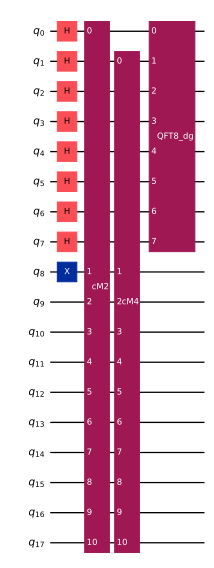

In [2]:
for case in study["cases"]:
    assert case["simulation"]["performed"]
    assert case["simulation"]["max_probability_error"] < 1e-10
    assert abs(case["simulation"]["work_register_zero_probability"] - 1) < 1e-10
    assert hashlib.sha256((data / case["qasm_file"]).read_bytes()).hexdigest() == case["qasm_sha256"]
display(SVG(filename=str(data / "circuit.svg")))

## Same frequency, two recovery rules

Every frequency row is retained. The 16 seeded draws per case are identical for both methods; failed factor extractions remain in the record. The bars are full-distribution ideal probabilities, not QPU measurements or general confidence guarantees.

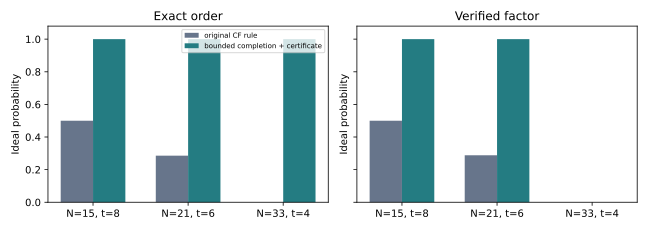

{'N': 15, 't': 8, 'baseline_exact_order': 0.5, 'recovery_certified_exact_order': 1.0, 'baseline_verified_factor': 0.5, 'recovery_verified_factor': 1.0}
{'N': 21, 't': 6, 'baseline_exact_order': 0.2857707365120908, 'recovery_certified_exact_order': 1.0, 'baseline_verified_factor': 0.2879891370365606, 'recovery_verified_factor': 1.0}
{'N': 33, 't': 4, 'baseline_exact_order': 0.0, 'recovery_certified_exact_order': 1.0, 'baseline_verified_factor': 0.0, 'recovery_verified_factor': 0.0}


In [3]:
display(SVG(filename=str(data / "success.svg")))
for case in study["cases"]:
    assert case["all_outcomes_retained"]
    assert len(case["all_frequency_rows"]) == 1 << case["phase_bits"]
    assert case["samples"]["same_draws_for_both_methods"]
    assert case["samples"]["trial_count"] == 16
    assert case["all_frequency_recovery_uses_smooth_only_pretest"]
    print({"N":case["modulus"], "t":case["phase_bits"], **case["weighted_success"]})

## Certificate and a preserved bad factoring base

A false candidate may complete to an order multiple. The separately charged certificate factors the returned period (not N) and checks minimality witnesses. All N33/a2 outcomes yield the exact order ten, but its half-power is −1, so no factor is obtained. Four phase bits are outside that case's CF theorem precision regime; the wholly smooth classical shortcut does not use the phase promise.

In [4]:
false_candidate = recover_frequency(23, 2, 46, 10, RecoveryConfig(offset_radius=0))
assert false_candidate["period"] == 22
assert false_candidate["certified_order"] is None
assert false_candidate["certificate"]["status"] == "period_is_not_minimal"
negative = recover_frequency(33, 2, 0, 4)
assert negative["certified_order"] == 10 and negative["factors"] == []
print({"false_candidate_period":false_candidate["period"], "exact_order_certified":False,
       "negative_order":negative["certified_order"], "negative_factors":negative["factors"]})

{'false_candidate_period': 22, 'exact_order_certified': False, 'negative_order': 10, 'negative_factors': []}


## Nearby frequencies for a nonsmooth path

This is an explicitly supplied synthetic integer frequency, not another quantum execution. Both calls use the same observed value 70. Full ±1 search includes an optimal neighbor; no true-order answer is passed to recovery.

In [5]:
direct = recover_frequency(59, 2, 70, 12, RecoveryConfig(offset_radius=0))
nearby = recover_frequency(59, 2, 70, 12, RecoveryConfig(offset_radius=1))
assert direct["certified_order"] is None
assert nearby["certified_order"] == 58
assert nearby["order_reference_used"] is False
print({"supplied_frequency":70, "direct_order":direct["certified_order"],
       "nearby_order":nearby["certified_order"], "examined":nearby["examined_offsets"]})

{'supplied_frequency': 70, 'direct_order': None, 'nearby_order': 58, 'examined': [{'offset': 0, 'frequency': 70, 'candidate': 59}, {'offset': 1, 'frequency': 71, 'candidate': 58}, {'offset': -1, 'frequency': 69, 'candidate': 59}]}


## Complete quantum workload and separate classical work

The fixed 16 complete quantum trials are unchanged between methods. Counts below are module-level algorithm counters and saved logical circuit counts, not physical time or CPython instruction counts. CPU simulation/check time, classical processing, and future calibrated feedback/interface cost are separate.

In [6]:
rows=[]
for case in study["cases"]:
    assert case["complete_quantum_work_for_fixed_samples"]["unchanged_between_postprocessors"]
    for method in ("baseline","recovery"):
        work=case["probability_weighted_classical_work"][method]
        rows.append([case["modulus"],method,f"{work['modular_pow_calls']:.3f}",
                     f"{work['modular_pow_exponent_bits']:.3f}",f"{work['certificate_trial_divisions']:.3f}",
                     case["complete_quantum_work_for_fixed_samples"]["primitive_operations"]])
headers=["N","Method","Expected modular powers","Expected exponent bits","Expected period-cert divisions","Same16-trial primitive operations"]
html="<table><thead><tr>"+"".join("<th>"+str(x)+"</th>" for x in headers)+"</tr></thead><tbody>"
html+="".join("<tr>"+"".join("<td>"+str(x)+"</td>" for x in row)+"</tr>" for row in rows)+"</tbody></table>"
display(HTML(html))

N,Method,Expected modular powers,Expected exponent bits,Expected period-cert divisions,Same16-trial primitive operations
15,baseline,1.750,4.500,0.000,140752
15,recovery,11.000,27.000,3.000,140752
21,baseline,1.814,4.712,0.000,724416
21,recovery,14.000,38.000,2.000,724416
33,baseline,1.641,5.562,0.000,757040
33,recovery,14.000,44.000,2.000,757040


## Optional local recovery control

A live kernel can change a synthetic frequency and offset radius. The static book executes one deterministic example instead of creating widget output. Neither control launches a circuit simulator or physical estimator.

In [7]:
def inspect_frequency(frequency=70, radius=1):
    answer=recover_frequency(59,2,int(frequency),12,RecoveryConfig(offset_radius=int(radius)))
    print({"frequency":frequency,"status":answer["status"],"period":answer["period"],
           "certified_order":answer["certified_order"],"work":answer["work"]})
if os.environ.get("OPENQUANTUM_STATIC_BUILD") == "1":
    inspect_frequency()
else:
    import ipywidgets as widgets
    widgets.interact(inspect_frequency,frequency=widgets.IntSlider(value=70,min=0,max=127),
                     radius=widgets.IntSlider(value=1,min=0,max=4))

{'frequency': 70, 'status': 'exact_order_certified', 'period': 58, 'certified_order': 58, 'work': {'euclidean_divisions': 11, 'sieve_marks': 2, 'integer_products': 32, 'modular_pow_calls': 14, 'modular_pow_exponent_bits': 66, 'maximum_exponent_bits': 6, 'certificate_trial_divisions': 4, 'gcd_calls': 3}}


## References and limits

The method follows Ekerå, *On the Success Probability of Quantum Order Finding*, DOI10.1145/3655026; exact pinned MITQuaspy routines are source references, not imported dependencies. The implementation caps modulus bits128, phase bits256, radius32, smooth bound512, modular powers8192 per frequency, and candidate-period certification at10^6. Circuit simulation is separately capped at18 wires. Physical costing and mechanized proof/circuit correspondence remain pending.